---
title: Sales Forecasting with Time-Varying Autoregressive Models (Part 4)
subtitle: Forecast real sales data
author: Kobus Esterhuysen
date: '2024-06-19'
date-modified: last-modified
categories:
  - Bayesian Inference
  - Autoregressive (AR) Models
  - Active Inference
  - RxInfer
  - Julia
image: SalesForecastingWithTVAR-AR.jpeg
format:
  html:
    toc: true
    toc-depth: 4
    toc-expand: true
    toc-title: TOC
    code-fold: false
---

In [1]:
#| hide
# BASED ON
  # SalesForecastingWithTVAR-AR3_PORT^v1.ipynb
  # SalesForecastingWithTVAR-AR2_PORT^v3.ipynb
  # SalesForecastingWithTVAR-AR2_PORT^v2.ipynb
  # SalesForecastingWithTVAR-AR2_PORT^v1.ipynb
  # Autoregressive Models_ANNO^v5.ipynb
  # Autoregressive Models_ANNO^v4.ipynb
  # Autoregressive Models_ANNO^v3.ipynb
  # Autoregressive Models_ANNO^v2.ipynb
  # Autoregressive Models.ipynb
# PUBLISH DEPENDENCIES
  # XXX_PORT.ipynb
# DONE
# v1 starts ------------------------------------------------
# migrated to RxInfer 3.0.0
# brought over my changes from RxInfer v2.16.2
# v2 starts ------------------------------------------------
# Change _n -> _N
# Change x -> s (state)
# Change order -> Mᴬᴿ
# Change θ, γ, τ -> θ̃, γ̃, τ̃
# Change states -> s̃s
# Change observations -> ys
# Change artype & T -> 𝚃ᴬᴿ
# standardize symbols to DeVries
# add math symbols to plots
# replace code vars with math symbols
  # makes mapping between literature and code better to enhance understanding
  # make expressions more concise due to reduced wordyness
# v3 starts ------------------------------------------------  
# Change generate_ar_data() to use matrices (small epsilon in V matrix so as not to break)
  # get error: AR-1 performs better than AR-5...
  # generated data appears somewhat different
  # parameters convert to different values (plot looks quite different)
  # I suspect sampling with the MvNormal is the culprit even though I tried with 1e-12*tiny
  # Will keep the matrix code for future, for now switch back to original code
# v4 starts ------------------------------------------------
# Change c -> v_u
# study posterior distributions
# plot θ_1,t tentatively to understand better
# Standardize plot colors
# Add alpha to ribbon plot to make it lighter
# v1 starts ------------------------------------------------
# Consolidate all initialization = ar_init(_Mᴬᴿ) into one function (i.e. also for M=1)
# Use multiple orders to find best model for synthetic data
# v2 starts ------------------------------------------------
# Publish
# v3 starts ------------------------------------------------
# Adjust transition & observation precisions
# Forecast into the future
# Two versions of generate_ar_data() function: with/without matrices
# Add offset to make sales positive
# Publish Part 3
# v1 starts ------------------------------------------------

# TODO
# Use shampoo sales data
# Add AR diagram
# Do experiments similar to 6.1 of paper
  # https://www2.stat.duke.edu/courses/Fall99/sta290/Notes/AR/ar.pdf
# Insert 6 methods ?
# Insert (modified) CRISP-DM structure
# Update narrative
# Replace hardcoded parameters with symbols

In Part 3 we did the first forecast beyond the available synthetic data. In this part, we make use of real sales data. As before, we use `RxInfer` to learn the best order (2) as well as the parameters $\boldsymbol\theta$ of the AR process. The inference process also learned the value of the transition precision parameter $\gamma$ as well as the $s_t$ state component which is the most recent sales amount.


In [2]:
versioninfo() ## Julia version

Julia Version 1.10.0
Commit 3120989f39b (2023-12-25 18:01 UTC)
Build Info:
  Official https://julialang.org/ release
Platform Info:
  OS: Linux (x86_64-linux-gnu)
  CPU: 12 × Intel(R) Core(TM) i7-8700B CPU @ 3.20GHz
  WORD_SIZE: 64
  LIBM: libopenlibm
  LLVM: libLLVM-15.0.7 (ORCJIT, skylake)
  Threads: 1 on 12 virtual cores
Environment:
  JULIA_NUM_THREADS = 


In [3]:
import Pkg
Pkg.add(Pkg.PackageSpec(;name="RxInfer", version="3.0.0"))
Pkg.add(Pkg.PackageSpec(;name="Distributions", version="0.25.108"))
Pkg.add(Pkg.PackageSpec(;name="Random"))
Pkg.add(Pkg.PackageSpec(;name="Plots", version="1.40.1"))
Pkg.add(Pkg.PackageSpec(;name="LaTeXStrings", version="1.3.1"))
Pkg.add(Pkg.PackageSpec(;name="BenchmarkTools", version="1.5.0"))
Pkg.add(Pkg.PackageSpec(;name="Parameters", version="0.12.3"))
Pkg.add(Pkg.PackageSpec(;name="CSV", version="0.10.14"))
Pkg.add(Pkg.PackageSpec(;name="DataFrames", version="1.6.1"))

using RxInfer, Distributions, LinearAlgebra, Random, Plots, LaTeXStrings, BenchmarkTools, Parameters
using DataFrames, CSV

   Resolving package versions...
  No Changes to `~/.julia/environments/v1.10/Project.toml`
  No Changes to `~/.julia/environments/v1.10/Manifest.toml`
   Resolving package versions...
  No Changes to `~/.julia/environments/v1.10/Project.toml`
  No Changes to `~/.julia/environments/v1.10/Manifest.toml`
   Resolving package versions...
  No Changes to `~/.julia/environments/v1.10/Project.toml`
  No Changes to `~/.julia/environments/v1.10/Manifest.toml`
   Resolving package versions...
  No Changes to `~/.julia/environments/v1.10/Project.toml`
  No Changes to `~/.julia/environments/v1.10/Manifest.toml`
   Resolving package versions...
  No Changes to `~/.julia/environments/v1.10/Project.toml`
  No Changes to `~/.julia/environments/v1.10/Manifest.toml`
   Resolving package versions...
  No Changes to `~/.julia/environments/v1.10/Project.toml`
  No Changes to `~/.julia/environments/v1.10/Manifest.toml`
   Resolving package versions...
  No Changes to `~/.julia/environments/v1.10/Project.to

In [4]:
Pkg.status()

Status `~/.julia/environments/v1.10/Project.toml`
  [6e4b80f9] BenchmarkTools v1.5.0
  [336ed68f] CSV v0.10.14
  [a93c6f00] DataFrames v1.6.1
⌃ [31c24e10] Distributions v0.25.108
  [b964fa9f] LaTeXStrings v1.3.1
  [d96e819e] Parameters v0.12.3
⌃ [91a5bcdd] Plots v1.40.1
⌃ [86711068] RxInfer v3.0.0
  [9a3f8284] Random
Info Packages marked with ⌃ have new versions available and may be upgradable.


In [5]:
## macro h(x) ## for help
#     quote
#         display("text/markdown", @doc $x)
#     end    
# end
# @h Normal() ## help on Normal()

Our model for the Variational Bayesian Inference of a latent autoregressive model can be represented mathematically as follows:

$$\begin{aligned}
p(\gamma) &= \mathcal{Gam}(\gamma|a, b)\\
p(\boldsymbol{\theta}) &= \mathcal{N}(\boldsymbol{\theta}|\mathbf{m}_{\theta}, \mathbf{V}_{\theta})\\
p(\mathbf{s}_t \mid \mathbf{s}_{t-1}, \boldsymbol{\theta}) &= \mathcal{N}\left(\mathbf{s}_t \mid \mathbf{B}\left(\boldsymbol{\theta}\right) \mathbf{s}_{t-1},\, \mathbf{V}(\gamma)\right)\\
p(x_t \mid \mathbf{s}_t) &= \mathcal{N}(x_t \mid \mathbf{s}_t, \tau^{-1})
\end{aligned}$$

where 

- $M^{AR}$ is the order of the autoregression process

- $\boldsymbol{\theta}=(\theta_1, \theta_2, ..., \theta_{M^{AR}})^{\top}$ is a vector of transition coefficients

- $\mathbf{s}_{t-1} = (s_{t-1}, s_{t-2}, ..., s_{t-M^{AR}})^\top$ is the previous state

- $\mathbf{s}_t = (s_{t}, s_{t-1}, ..., s_{t-M^{AR}+1})^\top$ is the current state

- $\gamma$ is the transition precision

- $\tau$ is the observation precision

- $\mathbf{v}_u = (1,0,...,0)^\top$ is an $M^{AR}$-dimensional unit vector selecting the first component of the vector that follows

- $\mathbf{V}(\gamma) = (1/ \gamma)\mathbf{v}_u\mathbf{v}_u^\top$ is the transition covariance

- $\mathbf{B}(\boldsymbol{\theta}) = \begin{bmatrix} 
\boldsymbol{\qquad\theta}^\top \\ 
\mathbf{I}_{M^{AR}-1} & \mathbf{0} 
\end{bmatrix}$ is the transition matrix

We downloaded the shampoo sales data from:

https://raw.githubusercontent.com/jbrownlee/Datasets/master/shampoo.csv

In [6]:
df = CSV.read("./shampoo.csv", DataFrame; delim=',')
df

Row,Month,Sales
,Date,Float64
1,0001-01-01,266.0
2,0001-02-01,145.9
3,0001-03-01,183.1
4,0001-04-01,119.3
5,0001-05-01,180.3
6,0001-06-01,168.5
7,0001-07-01,231.8
8,0001-08-01,224.5
9,0001-09-01,192.8


In [7]:
_ys = df.Sales

36-element Vector{Float64}:
 266.0
 145.9
 183.1
 119.3
 180.3
 168.5
 231.8
 224.5
 192.8
 122.9
   ⋮
 439.3
 401.3
 437.4
 575.5
 407.6
 682.0
 475.3
 581.3
 646.9

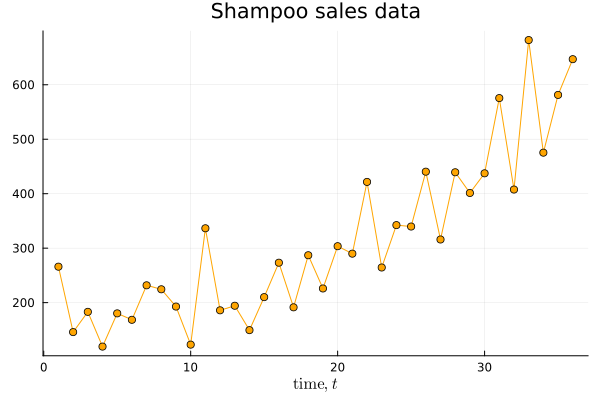

In [8]:
plot(
    # 1:_N,
    _ys, 
    title="Shampoo sales data",
    xlabel=L"$\mathrm{time}, t$",
    color="orange",
    legend=false
    # label=L"$\mathrm{Hidden\ state\ component}, \tilde{s}_t$",
) #.
scatter!(_ys, label=L"$\mathrm{Observation}, y_t$", color="orange")

In [9]:
#/// _f = .02 ## Frequency of a sine wave (Hz)
# _ω = 2π*_f
# _θˢⁱⁿᵉ = [2cos(_ω), -1]

In [10]:
#/// function generate_sales_data_nonmatrix(
# rng, ## random number generator
# N, ## number of data points 
# θ̃, ## AR parameters
# γ̃, ## transition precision
# τ̃) ## observation precision
#     Mᴬᴿ = length(θ̃) ## order of process
#     s̃ = Vector{Vector{Float64}}(undef, N + 3Mᴬᴿ)
#     y = Vector{Float64}(undef, N + 3Mᴬᴿ)
#     γ̃_std = sqrt(inv(γ̃)) ## transition standard dev
#     τ̃_std = sqrt(inv(τ̃)) ## observation standard dev
#     s̃[1] = randn(rng, Mᴬᴿ) ## Mᴬᴿ random numbers

#     ## +++ Matrix implementation
#     ## --- 
#     for t in 2:(N + 3Mᴬᴿ)
#         s̃[t] = vcat(
#             rand( ##. noised current value is pushed in at the top of state vector
#                 rng, 
#                 Normal(dot(θ̃, s̃[t-1]), γ̃_std)
#             ), 
#             s̃[t-1][1:end-1] ##. rest shifted down, last element pushed out & lost
#         )
#         ## s̃[t] = rand(rng, MvNormal(BIθₜI*s̃[t-1], VIγI)) ##. Eq (2b)

#         y[t] = rand(rng, Normal(s̃[t][1], τ̃_std))
#         ## y[t] = rand(rng, Normal(transpose(vᵤ)*s̃[t], τ̃_std)) ##. Eq (2c)
#     end
    
#     return s̃[1+3Mᴬᴿ:end], y[1+3Mᴬᴿ:end] #.
# end

In [11]:
#/// function generate_sales_data_matrix(
# rng, ## random number generator
# N, ## number of data points 
# θ̃, ## AR parameters
# γ̃, ## transition precision
# τ̃) ## observation precision
#     Mᴬᴿ = length(θ̃) ## order of process
#     s̃ = Vector{Vector{Float64}}(undef, N + 3Mᴬᴿ)
#     y = Vector{Float64}(undef, N + 3Mᴬᴿ)
#     γ̃_std = sqrt(inv(γ̃)) ## transition standard dev
#     τ̃_std = sqrt(inv(τ̃)) ## observation standard dev
#     s̃[1] = randn(rng, Mᴬᴿ) ## Mᴬᴿ random numbers

#     ## +++ Matrix implementation
#     ## Build BIθₜI, the transition matrix
#     Iₘ₋₁ = Diagonal(ones(Mᴬᴿ - 1))
#     V0 = Vector(zeros(Mᴬᴿ - 1)) ##vector of zeros
#     Bᵇᵒᵗᵗᵒᵐ = hcat(Iₘ₋₁, V0)
#     θₜ = θ̃
#     BIθₜI = vcat(transpose(θₜ), Bᵇᵒᵗᵗᵒᵐ)
#     ## Build VIγI, the transition covariance matrix
#     vᵤ = Vector(vcat(1.0, zeros(Mᴬᴿ - 1)))
#     VIγI = (1/γ̃)*vᵤ*transpose(vᵤ)
#     for i in 2:Mᴬᴿ
#         VIγI[i, i] = 1e-12*tiny ##tiny values on remaining off-diagonals to avoid PosDefException
#     end
#     ## --- 
#     for t in 2:(N + 3Mᴬᴿ)
#         s̃[t] = rand(rng, MvNormal(BIθₜI*s̃[t-1], VIγI)) ##. Eq (2b)
#         y[t] = rand(rng, Normal(transpose(vᵤ)*s̃[t], τ̃_std)) ##. Eq (2c)
#     end
    
#     return s̃[1+3Mᴬᴿ:end], y[1+3Mᴬᴿ:end] #.
# end

In [12]:
# ## Seed for reproducibility
# _seed = 123
# _rng  = MersenneTwister(_seed)

## Number of observations in synthetic dataset
# _N = 300
_N = 36

# ## AR process parameters
# _γ̃ = 0.1 ## real γ (transition precision)

_τ̃ = 0.001 ## assumed observation precision
# _τ̃ = 1.0 ## assumed observation precision
# _τ̃ = 0.1 ## assumed observation precision
# _τ̃ = 0.01 ## assumed observation precision

# _θ̃ = _θˢⁱⁿᵉ ## real θ (AR parameters)

# ## _s̃s, _ys = generate_sales_data_nonmatrix(_rng, _N, _θ̃, _γ̃, _τ̃);
# _s̃s, _ys = generate_sales_data_matrix(_rng, _N, _θ̃, _γ̃, _τ̃);

0.001

///First, we offset the generated values to make the sales data positive:

In [13]:
#/// offset = 500.0
# _s̃s = _s̃s + [[offset, offset] for i=1:_N]
# _ys = _ys + [offset for i=1:_N];

Now we specify a probabilistic model, the inference constraints and then run an inference procedure with `RxInfer`. We need two different models for:

- Multivariate AR, with order $M^{AR} > 1$

- Univariate AR (reduces to a simple State-Space-Model), with order $M^{AR}$ = 1

In [14]:
@model function lar_model(
x, ##. data/observations 
𝚃ᴬᴿ, ##. Uni/Multi variate 
Mᴬᴿ, ##. AR order
vᵤ, ##. unit vector 
τ) ##. observation precision     
    ## Priors
    γ  ~ Gamma(α = 1.0, β = 1.0) ##. for transition precision    
    if 𝚃ᴬᴿ === Multivariate
        θ  ~ MvNormal(μ = zeros(Mᴬᴿ), Λ = diageye(Mᴬᴿ)) ##.kw μ,Λ only work inside macro
        s₀ ~ MvNormal(μ = zeros(Mᴬᴿ), Λ = diageye(Mᴬᴿ)) ##.kw μ,Λ only work inside macro
    else ## Univariate
        θ  ~ Normal(μ = 0.0, γ = 1.0)
        s₀ ~ Normal(μ = 0.0, γ = 1.0)
    end
    sₜ₋₁ = s₀
    for t in eachindex(x)
        s[t] ~ AR(sₜ₋₁, θ, γ) #.Eq (2b)
        if 𝚃ᴬᴿ === Multivariate
            x[t] ~ Normal(μ = dot(vᵤ, s[t]), γ = τ) #.Eq (2c)
        else
            x[t] ~ Normal(μ = vᵤ*s[t], γ = τ) #.Eq (2c)
        end
        sₜ₋₁ = s[t]
    end
end

In [15]:
@constraints function ar_constraints() 
    q(s₀, s, θ, γ) = q(s₀, s)q(θ)q(γ)
end

ar_constraints (generic function with 1 method)

In [16]:
@meta function ar_meta(𝚃ᴬᴿ, Mᴬᴿ, stype)
    AR() -> ARMeta(𝚃ᴬᴿ, Mᴬᴿ, stype)
end

ar_meta (generic function with 1 method)

In [17]:
@initialization function ar_init(𝚃ᴬᴿ, Mᴬᴿ)
    q(γ) = GammaShapeRate(1.0, 1.0)
    if 𝚃ᴬᴿ === Multivariate    
        q(θ) = MvNormalMeanPrecision(zeros(Mᴬᴿ), diageye(Mᴬᴿ))
    else ## Univariate
        q(θ) = NormalMeanPrecision(0.0, 1.0)
    end
end

ar_init (generic function with 1 method)

In [18]:
function run_inference(Nmodels)
    results = Vector{Any}(undef, Nmodels)
    for m = 1:Nmodels
        println("m = $m")
        if m > 1 𝚃ᴬᴿ = Multivariate elseif m === 1 𝚃ᴬᴿ = Univariate
        else error("m=$m which is not an allowed value.") end    
        results[m] = infer(
            model = lar_model(
                𝚃ᴬᴿ=𝚃ᴬᴿ, ## Uni/Multi variate
                Mᴬᴿ=m, ## AR order
                vᵤ=ReactiveMP.ar_unit(𝚃ᴬᴿ, m), ##. unit vector
                τ=_τ̃), ## observation precision
            data = (x=_ys,),
            constraints   = ar_constraints(),
            meta          = ar_meta(𝚃ᴬᴿ, m, ARsafe()),
            options       = (limit_stack_depth = 100,),
            initialization = ar_init(𝚃ᴬᴿ, m),
            returnvars    = (s=KeepLast(), γ=KeepEach(), θ=KeepEach()),
            free_energy   = true,
            iterations    = 100,
            showprogress  = false
        )
    end
    return(results)
end       

run_inference (generic function with 1 method)

Now we run the inference for $M^{AR}=1,2, ..., 7$:

In [19]:
## _results = run_inference(length(_θ̃) + 5)
# _results = run_inference(3)
_results = run_inference(7)

m = 1
m = 2
m = 3
m = 4
m = 5
m = 6
m = 7


7-element Vector{Any}:
 Inference results:
  Posteriors       | available for (γ, s, θ)
  Free Energy:     | Real[2307.28, 2306.57, 2306.14, 2305.47, 2304.17, 2300.56, 2281.64, 1974.21, 519.355, 294.064  …  233.459, 233.459, 233.459, 233.459, 233.459, 233.459, 233.459, 233.459, 233.459, 233.459]

 Inference results:
  Posteriors       | available for (γ, s, θ)
  Free Energy:     | Real[2310.67, 2309.05, 2308.53, 2307.72, 2305.85, 2298.13, 2217.31, 1287.08, 319.798, 308.913  …  224.107, 224.107, 224.107, 224.107, 224.107, 224.107, 224.107, 224.107, 224.107, 224.107]

 Inference results:
  Posteriors       | available for (γ, s, θ)
  Free Energy:     | Real[2314.14, 2311.41, 2310.77, 2309.86, 2307.58, 2296.03, 2149.49, 883.808, 338.662, 319.551  …  225.164, 225.164, 225.164, 225.164, 225.164, 225.164, 225.164, 225.164, 225.164, 225.164]

 Inference results:
  Posteriors       | available for (γ, s, θ)
  Free Energy:     | Real[2317.59, 2313.75, 2312.93, 2311.94, 2309.39, 2294.89, 2120.28

In [20]:
function plot_free_energy(results)
    p = plot(title="Bethe Free Energy", legend=:topright, xlabel="iterations")
    for m = 1:length(results)
        p = plot!(p, results[m].free_energy, label="AR$m")
    end
    return p
end

plot_free_energy (generic function with 1 method)

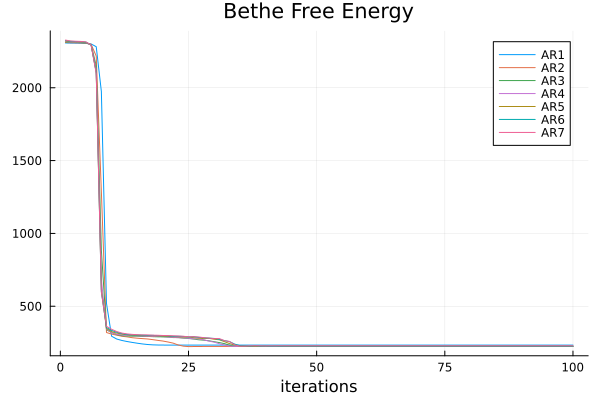

In [21]:
plot_free_energy(_results)

In [22]:
values = [_results[m].free_energy[end] for m in 1:length(_results)]

7-element Vector{Float64}:
 233.4585521436341
 224.10729518548234
 225.16366364288
 225.04948712417126
 225.2656225753958
 225.88766886863937
 228.36387001925232

In [23]:
function plot_converged_free_energy(results)
    values = [results[m].free_energy[end] for m in 1:length(results)]
    bar(
        1:length(results), 
        values, 
        legend=:none, 
        ylim=(200, 240), 
        title="Converged Free Energy vs AR Order"
    )
    xlabel!("AR order")
    ylabel!("Minimum Free Energy")
end

plot_converged_free_energy (generic function with 1 method)

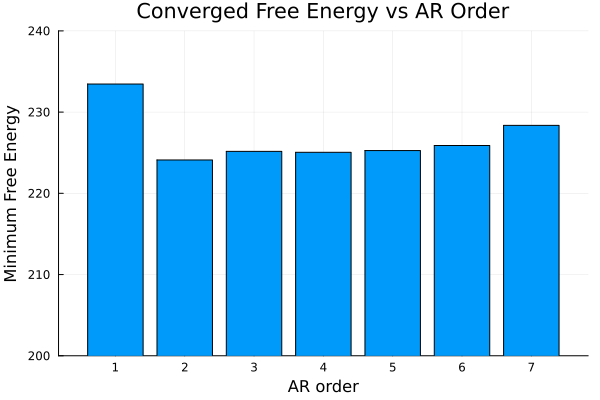

In [24]:
plot_converged_free_energy(_results)

In [25]:
function plot_transition_precision(results)
    p = plot(title="Inferred transition precision", legend=:topright, xlabel="iterations")
    for m = 1:length(results)
        p = plot!(p, mean.(results[m].posteriors[:γ]), label="AR$m")
    end
    ## plot!(
    ##     p, [_γ̃], seriestype=:hline, color="red", linestyle=:dash, 
    ##     label=L"Real transition precision $\tilde{γ}$"
    ## )
    return p
end

plot_transition_precision (generic function with 1 method)

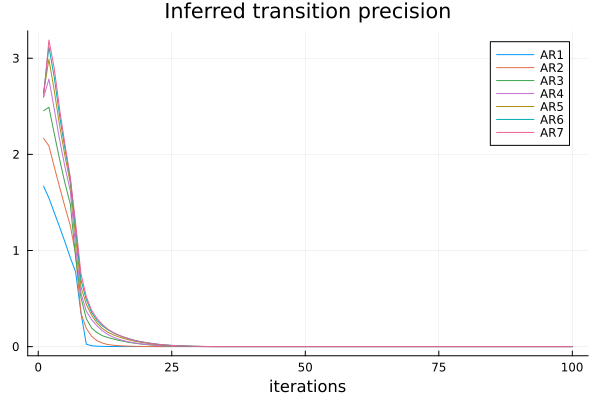

In [26]:
plot_transition_precision(_results)

In [27]:
# Mᵇᵉˢᵗ = 5 ## best order
Mᵇᵉˢᵗ = 2 ## best order
@unpack s, θ, γ = _results[Mᵇᵉˢᵗ].posteriors

Dict{Symbol, Vector} with 3 entries:
  :γ => GammaShapeRate{Float64}[GammaShapeRate{Float64}(a=19.0, b=8.76489), Gam…
  :s => MvNormalWeightedMeanPrecision{Float64, Vector{Float64}, Matrix{Float64}…
  :θ => MvNormalWeightedMeanPrecision{Float64, Vector{Float64}, Matrix{Float64}…

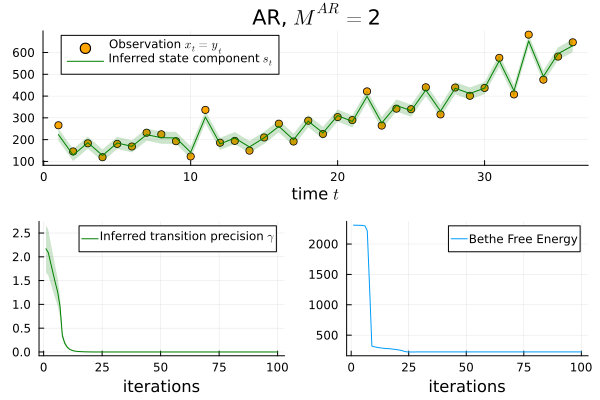

In [28]:
_p1 = plot(
    ## first.(_s̃s), ## first.() gives s̃ₜ, not the delayed s̃ₜ₋₁, s̃ₜ₋₂, ..., s̃ₜ₋ₘ₊₁
    title="AR, " * L"$M^{AR}=$" * "$Mᵇᵉˢᵗ",
    xlabel=L"time $t$",
    color="red",
    ## label=L"Hidden state component $\tilde{s}_t$"
)
_p1 = scatter!(_p1, _ys, label=L"Observation $x_t=y_t$", color="orange")
_p1 = plot!(
    _p1, first.(mean.(s)), 
    ribbon=first.(std.(s)), 
    fillalpha=0.2,
    label=L"Inferred state component $s_t$",
    color="green",
    legend=:topleft)

_p2 = plot(
    mean.(γ), ribbon=std.(γ), 
    fillalpha=0.2,
    label=L"Inferred transition precision $\gamma$", 
    color="green",
    legend=:topright,
    xlabel="iterations",
)
## _p2 = plot!(
##     [_γ̃], 
##     seriestype=:hline, 
##     color="red", #.
##     label=L"Real transition precision $\tilde{γ}$"
## )

_p3 = plot(_results[Mᵇᵉˢᵗ].free_energy, label="Bethe Free Energy", xlabel="iterations")
plot(_p1, _p2, _p3, layout=@layout([ a; b c ]))

Let's look at a smaller range of data for the sake of interest:

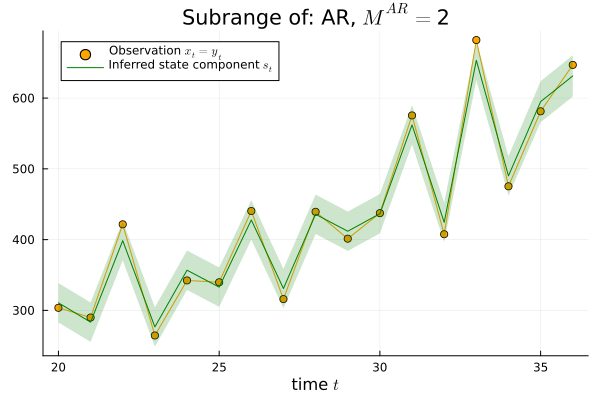

In [29]:
# _subrange = 200 : _N
_subrange = 20 : _N
plot(
    _subrange, 
    ## first.(_s̃s)[_subrange], 
    _ys[_subrange],
    title=L"Subrange of: AR, $M^{AR}=$"*"$Mᵇᵉˢᵗ",
    xlabel=L"time $t$",
    color="orange",
    label="",
)
scatter!(_subrange, _ys[_subrange], label=L"Observation $x_t=y_t$", color="orange")
plot!(
    _subrange, 
    first.(mean.(s))[_subrange],
    ribbon=sqrt.(first.(var.(s)))[_subrange],
    fillalpha=0.2,
    label=L"Inferred state component $s_t$",
    color="green",
    legend=:topleft
)

Finally, we look at how the learned AR coefficients converge:

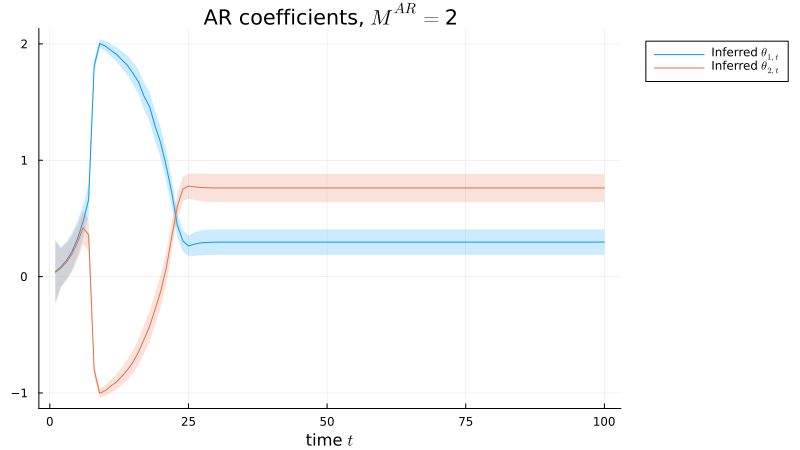

In [30]:
let
    pθ = plot()
    θms = mean.(θ) ##. θ means
    θvs = var.(θ) ##. θ variances
    l = length(θms)
    edim(e) = (a) -> map(r -> r[e], a)
    for t in 1:length(first(θms)) #.
        tmp = latexstring("\$ \\theta_{$(t),t} \$")
        pθ = plot!(
            pθ, 
            θms |> edim(t),
            ribbon=θvs |> edim(t) .|> sqrt, 
            fillalpha=0.2,
            label="Inferred $tmp")
    end
    ## for t in 1:length(_θ̃)
    ##     tmp = latexstring("\$ \\theta_{$(t),t} \$")
    ##     pθ = plot!(
    ##         pθ, 
    ##         [ _θ̃[t] ],
    ##         seriestype=:hline, 
    ##         label="Real $tmp")
    ## end
    plot(
        pθ, 
        title=L"AR coefficients, $M^{AR}=$"*"$Mᵇᵉˢᵗ",
        xlabel=L"time $t$",
        legend=:outertopright, 
        size=(800, 450))
end

Finally, we forecast a number of values into the future. First, we find the best value for $\theta$ and call it $\theta^{\mathrm{best}}$.

In [31]:
_θᵇᵉˢᵗ = mean(θ[end])

2-element Vector{Float64}:
 0.2965791124328563
 0.761818040823176

In [32]:
# _θᵇᵉˢᵗ[1], _θᵇᵉˢᵗ[2], _θᵇᵉˢᵗ[3], _θᵇᵉˢᵗ[4], _θᵇᵉˢᵗ[5]
_θᵇᵉˢᵗ[1], _θᵇᵉˢᵗ[2]

(0.2965791124328563, 0.761818040823176)

We decide to forecast 10 values into the future by having $n^{\mathrm{fcast}}=10$.

In [33]:
_nᶠᶜᵃˢᵗ = 10 ## number of forecast values

10

In [34]:
_sᶠᶜᵃˢᵗ = Vector{Float64}(undef, _nᶠᶜᵃˢᵗ);

In [35]:
## concat existing data with forecast to get complete signal
_sᶜᵒᵐᵖˡ = [first.(mean.(s)); _sᶠᶜᵃˢᵗ]

46-element Vector{Float64}:
 222.90905563878627
 129.1080133548282
 186.21297486503656
 127.37251396388952
 184.72878035452712
 169.14974001867415
 222.77794801609144
 208.92250166252228
 207.7460747904912
 141.80814711064664
   ⋮
   6.9459088367836e-310
   6.94590883597807e-310
   6.94580135762837e-310
   6.9458013579746e-310
   6.9458013576418e-310
   6.945801357641e-310
   6.94580135765446e-310
   6.94590985608845e-310
   6.9458013579738e-310

Now we calculate the forecast values:

In [36]:
for t in _N+1:_N+_nᶠᶜᵃˢᵗ
    # sᶜᵒᵐᵖˡ[t] = θᵇᵉˢᵗ[1]*sᶜᵒᵐᵖˡ[t-1] + θᵇᵉˢᵗ[2]*sᶜᵒᵐᵖˡ[t-2] + θᵇᵉˢᵗ[3]*sᶜᵒᵐᵖˡ[t-3] + θᵇᵉˢᵗ[4]*sᶜᵒᵐᵖˡ[t-4]
    _sᶜᵒᵐᵖˡ[t] = _θᵇᵉˢᵗ[1]*_sᶜᵒᵐᵖˡ[t-1] + _θᵇᵉˢᵗ[2]*_sᶜᵒᵐᵖˡ[t-2]
end
_sᶜᵒᵐᵖˡ

46-element Vector{Float64}:
 222.90905563878627
 129.1080133548282
 186.21297486503656
 127.37251396388952
 184.72878035452712
 169.14974001867415
 222.77794801609144
 208.92250166252228
 207.7460747904912
 141.80814711064664
   ⋮
 670.8915766914528
 686.8956411537476
 714.8162061472302
 735.2890475654945
 762.6312548243129
 786.3369623244342
 814.1973667801074
 840.519616449661
 869.5508046328555

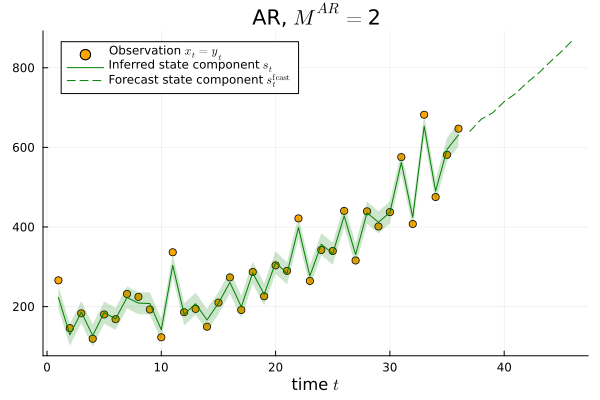

In [37]:
## _subrange = 1:_N
_subrange = 1:_N
_pc1 = plot(
    ## _subrange,
    ## first.(_s̃s)[_subrange], ## first.() gives s̃ₜ, not the delayed s̃ₜ₋₁, s̃ₜ₋₂, ..., s̃ₜ₋ₘ₊₁
    title="AR, " * L"$M^{AR}=$" * "$Mᵇᵉˢᵗ",
    xlabel=L"time $t$",
    ## color="red",
    ## label=L"Hidden state component $\tilde{s}_t$",
    legend=:topleft)
_pc1 = scatter!(_pc1, 
    _subrange,
    _ys[_subrange], label=L"Observation $x_t=y_t$", color="orange")
_pc1 = plot!(_pc1, 
    _subrange,
    first.(mean.(s))[_subrange], 
    ribbon=first.(std.(s))[_subrange], 
    fillalpha=0.2,
    label=L"Inferred state component $s_t$",
    color="green")
_pc1 = plot!(_pc1, 
    _N+1:_N+_nᶠᶜᵃˢᵗ,
    _sᶜᵒᵐᵖˡ[_N+1:_N+_nᶠᶜᵃˢᵗ],
    title="AR, " * L"$M^{AR}=$" * "$Mᵇᵉˢᵗ",
    xlabel=L"time $t$",
    color="green",
    linestyle=:dash,
    label=L"Forecast state component $s^{\mathrm{fcast}}_t$")